# Preprocessing airline passenger data

Split before fitting transformations so validation data does not influence imputation, scaling, or encoding. Keep the fitted pipeline for future predictions.

## 1. Load data


In [1]:
import pandas as pd

pd.set_option("display.max_columns", None)

df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

print("Training data:", df.shape)
print("Test data:", test_df.shape)
display(df.head())

Training data: (103904, 25)
Test data: (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


## 2. Prepare unrated service responses

A service rating of 0 means not rated. Create a binary `_not_rated` indicator (1 = not rated, 0 = rated), then replace zeros with missing values in copies of the training and test data. Only service-rating columns are changed; zero delays remain valid.

After the train/validation split, fill missing ratings with each column's median learned from rated training responses only. Apply the same medians to validation and test. This step prepares the indicators but deliberately leaves median imputation pending until that split. Indicators are added for every rating to keep the schema consistent.

In [2]:
rating_columns = [
    "Inflight wifi service", "Departure/Arrival time convenient",
    "Ease of Online booking", "Gate location", "Food and drink",
    "Online boarding", "Seat comfort", "Inflight entertainment",
    "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Cleanliness",
]

# Work on copies so the original data remains available.
df_prepared = df.copy()
test_prepared = test_df.copy()

for data in [df_prepared, test_prepared]:
    for col in rating_columns:
        data[f"{col}_not_rated"] = data[col].eq(0).astype("int8")
        data[col] = data[col].mask(data[col].eq(0))

rating_summary = pd.DataFrame({
    "train_not_rated": df[rating_columns].eq(0).sum(),
    "train_not_rated_percent": df[rating_columns].eq(0).mean().mul(100).round(2),
    "test_not_rated": test_df[rating_columns].eq(0).sum(),
})
display(rating_summary)
data.head()


,train_not_rated,train_not_rated_percent,test_not_rated
Inflight wifi service,3103,2.99,813
Departure/Arrival time convenient,5300,5.10,1381
Ease of Online booking,4487,4.32,1195
Gate location,1,0.00,0
Food and drink,107,0.10,25
Online boarding,2428,2.34,652
Seat comfort,1,0.00,0
Inflight entertainment,14,0.01,4
On-board service,3,0.00,2
Leg room service,472,0.45,126


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,Inflight wifi service_not_rated,Departure/Arrival time convenient_not_rated,Ease of Online booking_not_rated,Gate location_not_rated,Food and drink_not_rated,Online boarding_not_rated,Seat comfort_not_rated,Inflight entertainment_not_rated,On-board service_not_rated,Leg room service_not_rated,Baggage handling_not_rated,Checkin service_not_rated,Cleanliness_not_rated
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5.0,4.0,3.0,4,3.0,4.0,3,5.0,5.0,5.0,5,2,5,5.0,50,44.0,satisfied,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1.0,1.0,3.0,1,5.0,4.0,5,4.0,4.0,4.0,4,3,4,5.0,0,0.0,satisfied,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2.0,NaN,2.0,4,2.0,2.0,2,2.0,4.0,1.0,3,2,2,2.0,0,0.0,neutral or dissatisfied,0,1,0,0,0,0,0,0,0,0,0,0,0
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,NaN,NaN,NaN,2,3.0,4.0,4,1.0,1.0,1.0,1,3,1,4.0,0,6.0,satisfied,1,1,1,0,0,0,0,0,0,0,0,0,0
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2.0,3.0,4.0,3,4.0,1.0,2,2.0,2.0,2.0,2,4,2,4.0,0,20.0,satisfied,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3. Fill missing arrival delays

Calculate the arrival-delay median from `df_prepared`, then use it to fill missing arrival delays in `df_prepared` and `test_prepared`. Existing values, including zero delays, remain unchanged. No split is performed. For later validation, recalculate the median using only the training subset before filling its validation subset.

In [3]:
arrival_column = "Arrival Delay in Minutes"
arrival_median = df_prepared[arrival_column].median()
if pd.isna(arrival_median):
    raise ValueError("Cannot calculate the median: all arrival delays are missing.")

fill_summary = []
for name, data in [("Training data", df_prepared), ("Test data", test_prepared)]:
    missing_before = data[arrival_column].isna().sum()
    data[arrival_column] = data[arrival_column].fillna(arrival_median)
    fill_summary.append({"dataset": name, "filled_count": missing_before,
                         "missing_after": data[arrival_column].isna().sum()})

print(f"Arrival-delay median: {arrival_median:g} minutes")
display(pd.DataFrame(fill_summary).set_index("dataset"))


Arrival-delay median: 0 minutes


,filled_count,missing_after
dataset,,
Training data,310,0
Test data,83,0


## 4. Stratified train/validation split

Reserve 20% for validation, preserving satisfaction proportions with `stratify=y`. Use `random_state=42` for reproducibility. Exclude `id` and separate the 0/1 target. The external test data stays separate.

Recalculate arrival-delay imputation from original values using training indices only, replacing the earlier full-data imputation in the modeling subsets. Fit subsequent rating imputation, scaling, and encoding only on `X_train`.

In [4]:
from sklearn.model_selection import train_test_split

X = df_prepared.drop(columns=["id", "satisfaction"])
y = df_prepared["satisfaction"].map({
    "neutral or dissatisfied": 0,
    "satisfied": 1
})

if y.isna().any():
    raise ValueError("Unexpected satisfaction labels found")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.copy()
X_val = X_val.copy()
X_test = test_prepared[X.columns].copy()
test_ids = test_prepared["id"].copy()

# Recalculate arrival-delay imputation from the training subset only.
# Use original values because the previous cell already filled the prepared data.
arrival_column = "Arrival Delay in Minutes"
arrival_median = df.loc[X_train.index, arrival_column].median()
for data in [X_train, X_val]:
    data[arrival_column] = df.loc[data.index, arrival_column].fillna(arrival_median)
X_test[arrival_column] = test_df[arrival_column].fillna(arrival_median)

split_summary = pd.DataFrame({
    "all_count": y.value_counts(),
    "train_count": y_train.value_counts(),
    "validation_count": y_val.value_counts(),
    "all_percent": y.value_counts(normalize=True).mul(100),
    "train_percent": y_train.value_counts(normalize=True).mul(100),
    "validation_percent": y_val.value_counts(normalize=True).mul(100),
}).sort_index()
split_summary.index.name = "satisfaction"
display(split_summary.round(2))
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Training-only arrival-delay median:", arrival_median)


,all_count,train_count,validation_count,all_percent,train_percent,validation_percent
satisfaction,,,,,,
0,58879,47103,11776,56.67,56.67,56.67
1,45025,36020,9005,43.33,43.33,43.33


Training: (83123, 36)
Validation: (20781, 36)
Training-only arrival-delay median: 0.0


In [5]:
X.head()

,Unnamed: 0,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Inflight wifi service_not_rated,Departure/Arrival time convenient_not_rated,Ease of Online booking_not_rated,Gate location_not_rated,Food and drink_not_rated,Online boarding_not_rated,Seat comfort_not_rated,Inflight entertainment_not_rated,On-board service_not_rated,Leg room service_not_rated,Baggage handling_not_rated,Checkin service_not_rated,Cleanliness_not_rated
0,0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3.0,4.0,3.0,1.0,5.0,3.0,5.0,5.0,4.0,3.0,4,4.0,5,5.0,25,18.0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,Male,disloyal Customer,25,Business travel,Business,235,3.0,2.0,3.0,3.0,1.0,3.0,1.0,1.0,1.0,5.0,3,1.0,4,1.0,1,6.0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2,Female,Loyal Customer,26,Business travel,Business,1142,2.0,2.0,2.0,2.0,5.0,5.0,5.0,5.0,4.0,3.0,4,4.0,4,5.0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,3,Female,Loyal Customer,25,Business travel,Business,562,2.0,5.0,5.0,5.0,2.0,2.0,2.0,2.0,2.0,5.0,3,1.0,4,2.0,11,9.0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,4,Male,Loyal Customer,61,Business travel,Business,214,3.0,3.0,3.0,3.0,4.0,5.0,5.0,3.0,3.0,4.0,4,3.0,3,3.0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 5. New Preprocessing functions

In [6]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer

binary_cols = ['Gender', 'Customer Type', 'Type of Travel']
ordinal_cols = ['Class']
rating_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 
    'Ease of Online booking', 'Gate location', 'Food and drink', 
    'Online boarding', 'Seat comfort', 'Inflight entertainment', 
    'On-board service', 'Leg room service', 'Baggage handling', 
    'Checkin service', 'Cleanliness'
]
numeric_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

def encode_categorical(df_train, df_val, df_test=None):
    train, val = df_train.copy(), df_val.copy()
    test = df_test.copy() if df_test is not None else None

    # encode binary categorical columns
    binary_mapping = {
        'Gender': {'Male': 1, 'Female': 0},
        'Customer Type': {'Loyal Customer': 1, 'disloyal Customer': 0},
        'Type of Travel': {'Business travel': 1, 'Personal Travel': 0}
    }

    for col, mapping in binary_mapping.items():
        if col in train.columns:
            train[col] = train[col].map(mapping)
            val[col] = val[col].map(mapping)
            if test is not None:
                test[col] = test[col].map(mapping)
    
    # encode ordinal categorical columns
    class_order = [['Eco', 'Eco Plus', 'Business']]
    order_encoder = OrdinalEncoder(categories=class_order, handle_unknown='use_encoded_value', unknown_value=-1)

    train['Class'] = order_encoder.fit_transform(train[['Class']])
    val['Class'] = order_encoder.transform(val[['Class']])
    if test is not None:
        test['Class'] = order_encoder.transform(test[['Class']])

    return train, val, test

In [7]:
def impute_service_ratings(df_train, df_val, df_test=None):
    train, val = df_train.copy(), df_val.copy()
    test = df_test.copy() if df_test is not None else None

    # impute NaNs in ratings (converted from 0s) using median strategy
    imputer = SimpleImputer(strategy='median')
    train[rating_cols] = imputer.fit_transform(train[rating_cols])
    val[rating_cols] = imputer.transform(val[rating_cols])
    if test is not None:
        test[rating_cols] = imputer.transform(test[rating_cols])

    
    return train, val, test

In [8]:
def create_engineered_features(df):
    df = df.copy()
    
    # create delay features
    df['Total_Delay'] = df['Departure Delay in Minutes'] + df['Arrival Delay in Minutes']
    df['Delay_Difference'] = df['Arrival Delay in Minutes'] - df['Departure Delay in Minutes']
    df['Has_Delay'] = (df['Total_Delay'] > 0).astype(int)
    
    # aggregate service scores
    df['Mean_Rating'] = df[rating_cols].mean(axis=1)
    df['Max_Rating'] = df[rating_cols].max(axis=1)
    df['Min_Rating'] = df[rating_cols].min(axis=1)
    
    
    return df

In [9]:
def scale_continuous_features(df_train, df_val, cols_to_scale, df_test=None):
    train, val = df_train.copy(), df_val.copy()
    test = df_test.copy() if df_test is not None else None

    scaler = StandardScaler()
    train[cols_to_scale] = scaler.fit_transform(train[cols_to_scale])
    val[cols_to_scale] = scaler.transform(val[cols_to_scale])
    if test is not None:
        test[cols_to_scale] = scaler.transform(test[cols_to_scale])

    return train, val, test, scaler

In [10]:
def run_full_preprocessing(df_train, df_val, df_test=None):
    # 1. Categorical encoding
    X_tr, X_v, X_te = encode_categorical(df_train, df_val, df_test)

    # 2. Rating imputation
    X_tr, X_v, X_te = impute_service_ratings(X_tr, X_v, X_te)

    # 3. Feature engineering
    X_tr = create_engineered_features(X_tr)
    X_v = create_engineered_features(X_v)
    X_te = create_engineered_features(X_te) if X_te is not None else None
    
    # 4. Continuous feature scaling
    continuous_cols = numeric_cols + ['Total_Delay', 'Delay_Difference', 'Mean_Rating']
    X_tr, X_v, X_te, scaler = scale_continuous_features(X_tr, X_v, continuous_cols, X_te)
    
    return X_tr, X_v, X_te, scaler

## 6. Apply new preprocessing functions to train, validation, and test data

In [13]:
# run full preprocessing pipeline
X_train_proc, X_val_proc, X_test_proc, scaler = run_full_preprocessing(
    X_train, X_val, X_test
)

# verify pipeline
print("--- PREPROCESSING COMPLETE ---")
print(f"X_train_proc shape: {X_train_proc.shape}")
print(f"X_val_proc shape:   {X_val_proc.shape}")
print(f"X_test_proc shape:  {X_test_proc.shape if X_test_proc is not None else 'N/A'}")
print(f"Total NaNs remaining in X_train_proc: {X_train_proc.isna().sum().sum()}")
print(f"Total NaNs remaining in X_val_proc:   {X_val_proc.isna().sum().sum()}")

--- PREPROCESSING COMPLETE ---
X_train_proc shape: (83123, 42)
X_val_proc shape:   (20781, 42)
X_test_proc shape:  (25976, 42)
Total NaNs remaining in X_train_proc: 0
Total NaNs remaining in X_val_proc:   0


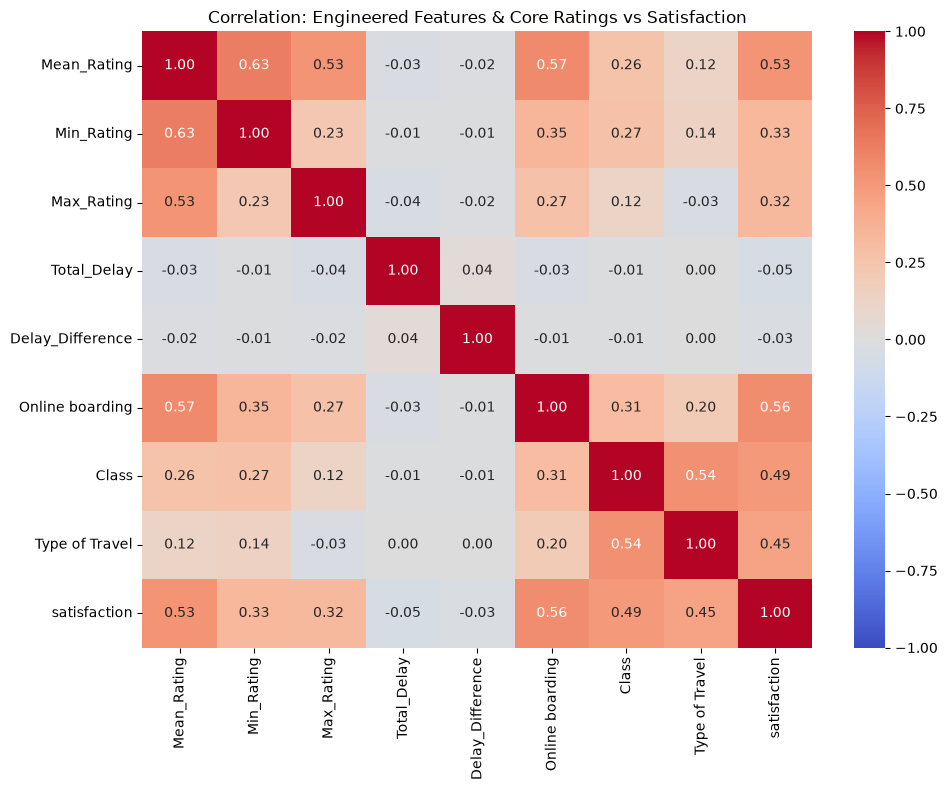

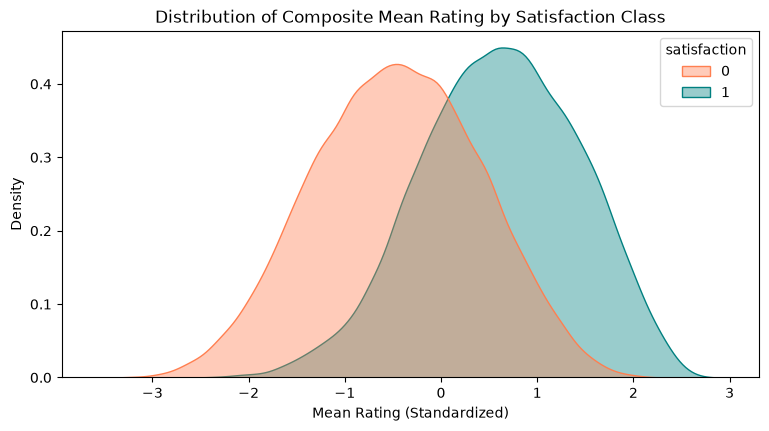

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Re-attach target temporarily for analysis
df_analysis = X_train_proc.copy()
df_analysis['satisfaction'] = y_train.values

# 1. Heatmap: Core Engineered Features vs Satisfaction
plt.figure(figsize=(10, 8))
key_cols = [
    'Mean_Rating', 'Min_Rating', 'Max_Rating', 
    'Total_Delay', 'Delay_Difference', 'Online boarding', 
    'Class', 'Type of Travel', 'satisfaction'
]
sns.heatmap(
    df_analysis[key_cols].corr(), 
    annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1
)
plt.title("Correlation: Engineered Features & Core Ratings vs Satisfaction")
plt.tight_layout()
plt.show()

# 2. KDE Plot: Scaled Mean Rating Separation
plt.figure(figsize=(9, 4.5))
sns.kdeplot(
    data=df_analysis, x='Mean_Rating', hue='satisfaction', 
    common_norm=False, fill=True, palette={0: 'coral', 1: 'teal'}, alpha=0.4
)
plt.title("Distribution of Composite Mean Rating by Satisfaction Class")
plt.xlabel("Mean Rating (Standardized)")
plt.ylabel("Density")
plt.show()